# Iterative magnitude pruning (IMP) on CIFAR-10

How much does subset selection change validation accuracy once the pruning method is fixed? The project has eight completed IMP sweeps. Each includes 18 subset selectors and one full-data IMP control. This notebook compares settings that differ in one experimental factor at a time.

[Training seeds](#training-seeds) · [Weight sparsity](#weight-sparsity) · [CIFAR-10 classes](#classes) · [Subset size and architecture](#matched-comparisons) · [All recorded accuracies](#all-results)

Every sparse model used **eight IMP rounds**, reset to its paired initialization, then trained for **200 epochs on all 45,000 training images**. The selected 9,000 or 11,250 images were used during mask discovery. Subset IMP used 14,080 discovery updates and full-data IMP used 70,400, so comparisons with full-data IMP change both the data available and the number of updates. Dense accuracy is the unpruned 200-epoch reference for that architecture and seed.

All accuracy measurements below use the same 5,000 validation images at epoch 200. One additional correct prediction changes accuracy by 0.02 percentage points (pp). To rerun it, start the kernel in the project root or its `results/` folder. It reads saved results and mask summaries and requires pandas, NumPy, Matplotlib, and IPython.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

project = Path.cwd().resolve()
if project.name == "results" and (project.parent / "run_experiments.py").is_file():
    project = project.parent
runs_dir = project / "runs"
if not runs_dir.is_dir():
    raise FileNotFoundError("The saved runs/ folder is required. Start the kernel in the repository root or its results/ folder.")

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "font.size": 10,
})
family_names = {
    "random": "Random", "feature_cluster": "Feature clustering",
    "gradient_cluster": "Gradient clustering", "loss": "Loss",
    "average_margin": "Average margin", "el2n": "EL2N",
    "gradient_norm": "Gradient norm", "forgetting": "Forgetting",
}
arch_names = {"resnet32": "ResNet-32", "vgg19": "VGG-19"}

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

def final_counts(metrics):
    per_class = metrics["per_class"].values()
    correct = sum(v["correct"] for v in per_class)
    total = sum(v["total"] for v in per_class)
    assert total == 5000 and abs(correct / total - metrics["accuracy"]) < 1e-8
    return correct, total

# An ID can appear again in another sweep directory with a different measured outcome.
imp_finals = {}
for result_file in sorted(runs_dir.rglob("final/*/validation.json")):
    result = read_json(result_file)
    if result["pruning"]["method"] == "imp":
        imp_finals[result_file] = result

records, class_records, used_paths = [], [], set()
for manifest in sorted(runs_dir.rglob("sweeps/*/execution.json")):
    root = manifest.parents[2]
    config = read_json(manifest.with_name("config.json"))
    events = read_json(manifest)["runs"]
    assert len({event["run"] for event in events}) == len(events)
    files = [root / "final" / event["run"] / "validation.json" for event in events]
    assert all(p.is_file() for p in files), f"Missing validation data in {manifest}"
    files = [p for p in files if p in imp_finals]
    if not files:
        continue
    arch, = config["architectures"]
    seed, = config["seeds"]
    fraction_value, = config["fractions"]
    sparsity_value, = config["sparsities"]
    fraction, sparsity = round(100 * fraction_value), round(100 * sparsity_value)
    recipe = imp_finals[files[0]]["recipe"]
    dense_results = [read_json(p) for p in (root / "baselines").glob("*/dense-validation.json")]
    dense_result, = [d for d in dense_results if d["recipe"] == recipe]
    assert len(dense_result["history"]) == 200
    dense_correct, dense_total = final_counts(dense_result["metrics"])
    for path in files:
        r = imp_finals[path]
        p = r["pruning"]
        assert r["partition"] == "validation" and r["epochs"] == r["history"][-1]["epoch"] == len(r["history"]) == 200
        assert r["recipe"] == recipe and (recipe["arch"], recipe["seed"], recipe["split_seed"]) == (arch, seed, 260)
        assert p["rounds"] == 8 and p["sparsity"] == sparsity_value and r["run"] == path.parent.name
        assert abs(r["history"][-1]["val_accuracy"] - r["metrics"]["accuracy"]) < 1e-8
        spec = r["subset_spec"]
        if spec:
            assert spec["fraction"] == fraction_value
            family, difficulty = family_names[spec["method"]], spec.get("difficulty", "")
        else:
            assert p["subset"] == "full"
            family, difficulty = "Full data", ""
        selector = f"{family} · {difficulty}" if difficulty else family
        mask = read_json(root / "masks" / r["mask"] / "summary.json")
        correct, total = final_counts(r["metrics"])
        assert mask["id"] == r["mask"] and mask["spec"] == p
        assert r["cost"]["discovery_updates"] == (14080 if spec else 70400)
        row = dict(arch=arch, seed=seed, fraction=fraction, sparsity=sparsity, selector=selector,
                   family=family, difficulty=difficulty, accuracy=100 * correct / total, correct=correct,
                   dense=100 * dense_correct / dense_total, eligible=mask["eligible"], surviving=mask["surviving"],
                   complete=True, sweep=manifest.parent.name, run=r["run"], split=r["split_id"],
                   source=str(path.relative_to(project)), subset_id=p["subset"])
        records.append(row)
        for label, counts in r["metrics"]["per_class"].items():
            assert counts["total"] == 500
            class_records.append({**row, "label": label, "class_accuracy": 100 * counts["correct"] / counts["total"]})
        used_paths.add(path)
assert used_paths == set(imp_finals), "Found an IMP result outside the completed manifests; inspect its provenance."
imp = pd.DataFrame(records)
imp_classes = pd.DataFrame(class_records)
cohort = ["arch", "seed", "fraction", "sparsity"]
assert imp["split"].nunique() == 1 and not imp.duplicated(cohort + ["selector"]).any()
assert imp.groupby(cohort)["selector"].nunique().eq(19).all()

### Which comparisons are available?

“Selector mean” gives equal weight to each of the 18 subset settings, including random. “Full-data IMP” uses all 45,000 training images to discover the mask. Every table that averages training seeds gives each seed equal weight.

In [2]:
subsets = imp[imp.selector.ne("Full data")]
inventory = subsets.groupby(cohort).agg(selectors=("selector", "count"), mean=("accuracy", "mean"))
inventory["Random IMP"] = imp.loc[imp.selector.eq("Random")].set_index(cohort)["accuracy"]
inventory["Full-data IMP"] = imp.loc[imp.selector.eq("Full data")].set_index(cohort)["accuracy"]
inventory["Dense"] = imp.groupby(cohort)["dense"].first()
inventory = inventory.reset_index().rename(columns={"arch": "Architecture", "seed": "Seed",
    "fraction": "Subset", "sparsity": "Sparsity", "selectors": "Selectors", "mean": "Selector mean"})
inventory["Architecture"] = inventory["Architecture"].map(arch_names)
display(inventory.style.hide(axis="index").format({
    "Subset": "{}%", "Sparsity": "{}%", **dict.fromkeys(["Selector mean","Random IMP","Full-data IMP","Dense"], "{:.2f}%")
}))
display(Markdown(f"**{len(inventory)} sweeps · {len(subsets)} subset results · {len(imp) - len(subsets)} full-data IMP measurements.** "
                 "The unfinished 20%-subset sweep at 95% sparsity has no saved IMP validation result."))

Architecture,Seed,Subset,Sparsity,Selectors,Selector mean,Random IMP,Full-data IMP,Dense
ResNet-32,0,20%,90%,18,90.73%,90.42%,89.92%,94.06%
ResNet-32,0,25%,80%,18,91.88%,91.94%,92.26%,94.06%
ResNet-32,0,25%,90%,18,90.73%,90.56%,90.14%,94.06%
ResNet-32,0,25%,95%,18,88.84%,89.88%,88.48%,94.06%
ResNet-32,0,25%,98%,18,84.89%,85.04%,83.78%,94.06%
ResNet-32,1,25%,90%,18,90.79%,91.06%,90.24%,93.88%
ResNet-32,2,25%,90%,18,90.75%,90.52%,90.74%,94.08%
VGG-19,0,25%,90%,18,93.23%,93.08%,94.04%,93.98%


**8 sweeps · 144 subset results · 8 full-data IMP measurements.** The unfinished 20%-subset sweep at 95% sparsity has no saved IMP validation result.

<a id="training-seeds"></a>

## Which selector gains repeat across training seeds?

These ResNet-32 experiments hold the validation split, 25% discovery subset size and 90% weight sparsity fixed. The figure compares each selector with the random-subset IMP model trained with the **same seed**. Each point is an epoch-200 validation result on 5,000 images. A gain of 0.20 percentage points corresponds to 10 more correct predictions.

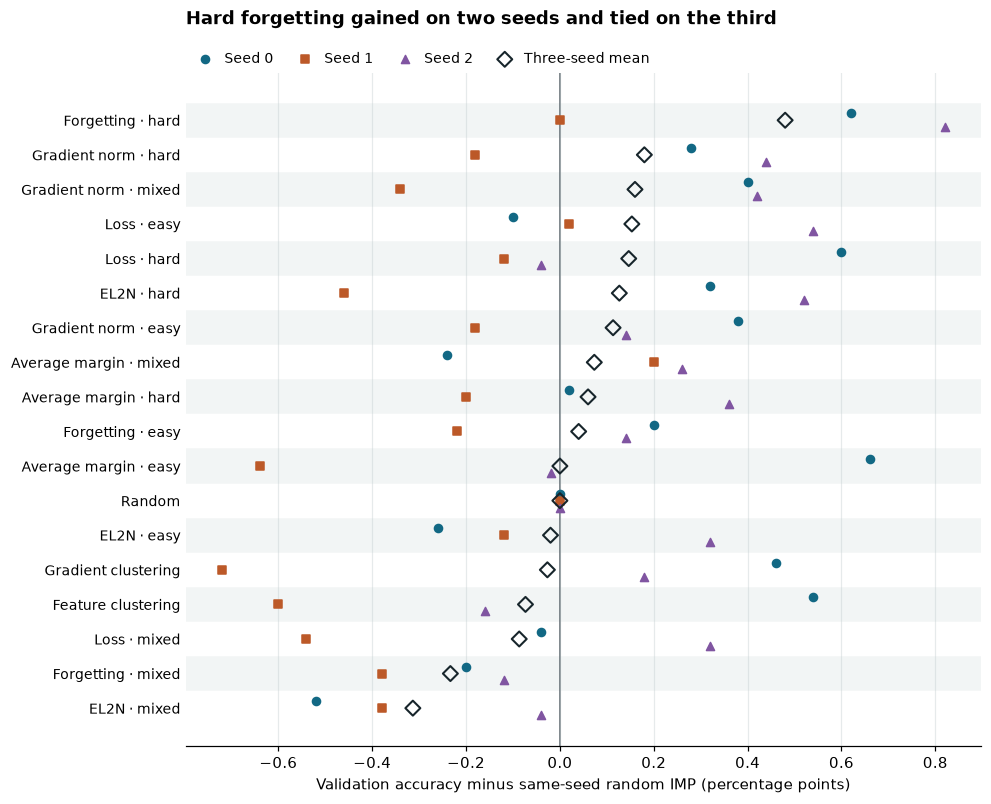

In [3]:
seed_runs = imp.loc[
    imp["complete"] & imp["arch"].eq("resnet32") & imp["fraction"].eq(25)
    & imp["sparsity"].eq(90) & imp["seed"].isin([0, 1, 2])
].copy()
seed_counts = seed_runs.pivot(index="selector", columns="seed", values="correct").reindex(columns=[0, 1, 2])
assert seed_counts.shape == (19, 3) and seed_counts.notna().all().all()
seed_accuracy = seed_counts * (100 / 5000)
paired_gain = seed_counts.sub(seed_counts.loc["Random"], axis="columns") * (100 / 5000)
subset_gain = paired_gain.drop(index="Full data")
seed_order = subset_gain.mean(axis=1).sort_values(ascending=False, kind="stable").index
gain_plot = subset_gain.loc[seed_order]

fig, ax = plt.subplots(figsize=(8.9, 7.2), layout="constrained")
y = np.arange(len(gain_plot))
for pos in y[::2]:
    ax.axhspan(pos - .48, pos + .48, color="#f2f5f5", zorder=0)
ax.axvline(0, color="#59636a", linewidth=1, zorder=1)
seed_marks = [(0, "o", "#126884", -.20), (1, "s", "#bc5928", 0), (2, "^", "#8055a1", .20)]
for seed_number, marker, color, offset in seed_marks:
    ax.scatter(gain_plot[seed_number], y + offset, label=f"Seed {seed_number}", marker=marker,
               color=color, s=28, zorder=3)
ax.scatter(gain_plot.mean(axis=1), y, label="Three-seed mean", marker="D", s=48,
           facecolor="none", edgecolor="#17252b", linewidth=1.35, zorder=4)
ax.set(yticks=y, yticklabels=seed_order, xlabel="Validation accuracy minus same-seed random IMP (percentage points)")
ax.invert_yaxis()
ax.tick_params(axis="y", length=0, labelsize=9)
ax.grid(axis="x", color="#c4ced0", alpha=.42, zorder=0)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.set_title("Hard forgetting gained on two seeds and tied on the third", loc="left", fontweight="bold", pad=32)
ax.legend(frameon=False, ncol=4, loc="lower left", bbox_to_anchor=(0, 1.002),
          borderaxespad=0, columnspacing=1.3, handletextpad=.4, fontsize=9)
plt.show()

In [4]:
contrast_names = ["Forgetting · hard", "Average margin · easy", "Random", "Full data"]
seed_contrasts = seed_accuracy.loc[contrast_names].copy()
seed_dense = seed_runs.groupby("seed")["dense"]
assert seed_dense.nunique().eq(1).all()
seed_contrasts.loc["Dense baseline"] = seed_dense.first()
seed_contrasts["Mean"] = seed_contrasts[[0, 1, 2]].mean(axis=1)
seed_contrasts = seed_contrasts.rename(index={"Full data": "Full-data IMP"}, columns={i: f"Seed {i}" for i in [0, 1, 2]})
display(seed_contrasts.style.format("{:.2f}%")
        .set_caption("Validation accuracy for the leading three-seed selector, the seed-0 leader and matched references"))

seed,Seed 0,Seed 1,Seed 2,Mean
selector,,,,
Forgetting · hard,91.18%,91.06%,91.34%,91.19%
Average margin · easy,91.22%,90.42%,90.50%,90.71%
Random,90.56%,91.06%,90.52%,90.71%
Full-data IMP,90.14%,90.24%,90.74%,90.37%
Dense baseline,94.06%,93.88%,94.08%,94.01%


Hard forgetting had the highest three-seed mean of the 18 selector settings, **91.19%**. Its gains over random were **+0.62, 0.00 and +0.82 percentage points** on seeds 0, 1 and 2. It exceeded full-data IMP on every seed. Easy average margin led seed 0 at **91.22%**, but tied random IMP at **90.71%** on the three-seed mean. The three training seeds share one validation split, so this measures sensitivity to training and selection randomness on those same images.

### Does selecting harder images help every scoring rule?

Each cell below gives the mean across three seeds. The last column compares the hard and mixed settings **within the same scoring rule**.

In [5]:
seed_scored = seed_runs.loc[seed_runs["difficulty"].isin(["easy", "hard", "mixed"])]
difficulty_by_rule = seed_scored.pivot_table(index="family", columns="difficulty", values="accuracy",
                                            aggfunc="mean")[["easy", "hard", "mixed"]]
assert difficulty_by_rule.shape == (5, 3) and len(seed_scored) == 45
difficulty_by_rule.loc["Mean across five rules"] = difficulty_by_rule.mean()
difficulty_by_rule["Hard minus mixed (pp)"] = difficulty_by_rule["hard"] - difficulty_by_rule["mixed"]
difficulty_by_rule = difficulty_by_rule.rename(columns={"easy": "Easy", "hard": "Hard", "mixed": "Mixed"})
display(difficulty_by_rule.style
        .format({"Easy": "{:.2f}%", "Hard": "{:.2f}%", "Mixed": "{:.2f}%", "Hard minus mixed (pp)": "{:+.2f}"})
        .set_caption("IMP at 90% sparsity, 25% discovery subsets and seeds 0–2"))

difficulty,Easy,Hard,Mixed,Hard minus mixed (pp)
family,,,,
Average margin,90.71%,90.77%,90.79%,-0.01
EL2N,90.69%,90.84%,90.40%,+0.44
Forgetting,90.75%,91.19%,90.48%,+0.71
Gradient norm,90.83%,90.89%,90.87%,+0.02
Loss,90.87%,90.86%,90.63%,+0.23
Mean across five rules,90.77%,90.91%,90.63%,+0.28


Across the five rules, hard averaged **90.91%**, easy **90.77%**, and mixed **90.63%**. The hard–mixed difference depended on the scoring rule. It was **+0.71 points** for forgetting and **+0.44** for EL2N, versus **+0.02** for gradient norm and **−0.01** for average margin. Forgetting showed the largest benefit from choosing hard examples.

<a id="weight-sparsity"></a>

## How much accuracy does IMP retain as the mask gets smaller?

ResNet-32, seed 0, 25% discovery subsets. This comparison follows the same 18 selector settings at 80%, 90%, 95%, and 98% sparsity. The shaded range shows the lowest and highest selector accuracies at each sparsity. It describes variation among selectors on this seed.

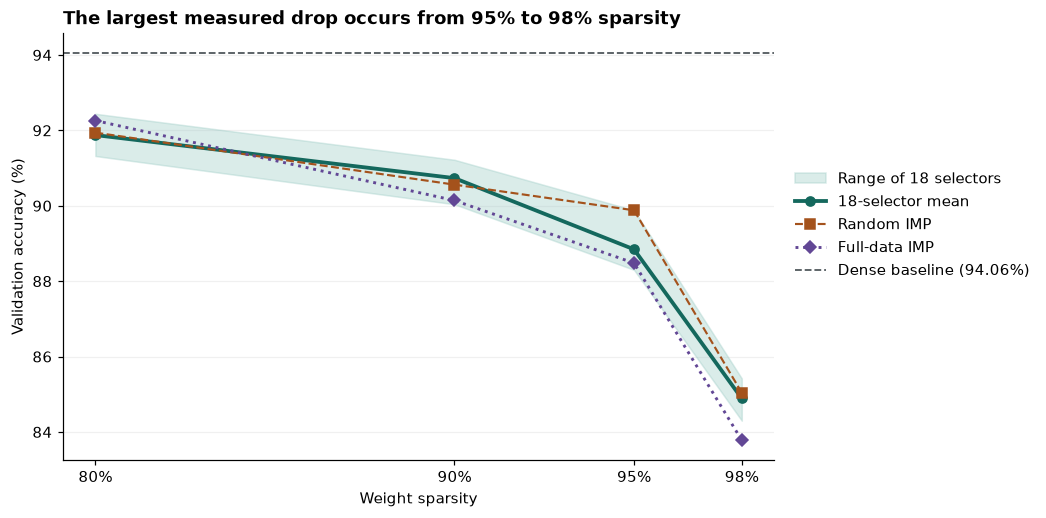

,Weights kept,Selector mean,Random IMP,Full-data IMP,Best selector,Best accuracy
Sparsity (%),,,,,,
80,"92,374",91.88%,91.94%,92.26%,Gradient norm · hard,92.44%
90,"46,187",90.73%,90.56%,90.14%,Average margin · easy,91.22%
95,"23,094",88.84%,89.88%,88.48%,Random,89.88%
98,"9,237",84.89%,85.04%,83.78%,Loss · mixed,85.42%


From 95% to 98%, **18 of 18** selectors lost accuracy. Their average loss was **3.96 pp**. The best setting also changed with sparsity: random IMP led at 95% (89.88%), and mixed loss led at 98% (85.42%). Both rankings come from seed 0.

In [6]:
levels = [80, 90, 95, 98]
s0 = imp.query("arch == 'resnet32' and seed == 0 and fraction == 25").copy()
grid = s0.pivot(index="selector", columns="sparsity", values="accuracy").loc[:, levels]
subset_grid = grid.drop(index="Full data")
assert subset_grid.shape == (18, 4) and subset_grid.notna().all().all()
trend = subset_grid.mean()
fig, ax = plt.subplots(figsize=(9.4, 4.6), layout="constrained")
ax.fill_between(levels, subset_grid.min(), subset_grid.max(), color="#9acbc4", alpha=.36,
                label="Range of 18 selectors")
ax.plot(levels, trend, "o-", lw=2.5, color="#14685d", label="18-selector mean")
ax.plot(levels, grid.loc["Random"], "s--", lw=1.4, color="#a4521c", label="Random IMP")
ax.plot(levels, grid.loc["Full data"], "D:", lw=1.9, color="#624795", label="Full-data IMP")
dense0, = s0.dense.unique()
ax.axhline(dense0, color="#545b60", lw=1.2, ls="--", label=f"Dense baseline ({dense0:.2f}%)")
ax.set(xticks=levels, xticklabels=[f"{v}%" for v in levels], xlabel="Weight sparsity",
       ylabel="Validation accuracy (%)", title="The largest measured drop occurs from 95% to 98% sparsity")
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=.18)
ax.legend(loc="center left", bbox_to_anchor=(1.01, .55), frameon=False)
plt.show()

trend_table = pd.DataFrame({
    "Weights kept": s0.groupby("sparsity").surviving.first(),
    "Selector mean": trend, "Random IMP": grid.loc["Random"], "Full-data IMP": grid.loc["Full data"],
    "Best selector": [", ".join(subset_grid.index[subset_grid[level].eq(subset_grid[level].max())]) for level in levels],
    "Best accuracy": subset_grid.max(),
}, index=levels).rename_axis("Sparsity (%)")
display(trend_table.style.format({"Weights kept":"{:,}", **dict.fromkeys(
    ["Selector mean","Random IMP","Full-data IMP","Best accuracy"], "{:.2f}%")}))
d95 = subset_grid[98] - subset_grid[95]
display(Markdown(f"From 95% to 98%, **{(d95 < 0).sum()} of {len(d95)}** selectors lost accuracy. "
                 f"Their average loss was **{-d95.mean():.2f} pp**. The best setting also changed with sparsity: "
                 f"random IMP led at 95% ({grid.at['Random', 95]:.2f}%), and mixed loss led at 98% "
                 f"({grid.at['Loss · mixed', 98]:.2f}%). Both rankings come from seed 0."))

The selector names are matched across sparsities. A repeat run can select slightly different images even with the same selector and seed. The following check reads the saved image IDs for the 95% and 98% sweeps.

In [7]:
ids_by_setting = {}
for row in s0[s0.sparsity.isin([95, 98]) & s0.selector.ne("Full data")].itertuples():
    run_root = (project / row.source).parents[2]
    selected = read_json(run_root / "subsets" / row.subset_id / "subset.json")
    ids_by_setting[row.sparsity, row.selector] = set(selected["ids"])
matched_selectors = [name for name in subset_grid.index
                     if ids_by_setting[95, name] == ids_by_setting[98, name]]
display(Markdown(f"**{len(matched_selectors)} of 18 selectors** used exactly the same 11,250 images at both sparsities. "
                 f"For this group, mean IMP accuracy fell by **{-d95.loc[matched_selectors].mean():.2f} pp**."))

**7 of 18 selectors** used exactly the same 11,250 images at both sparsities. For this group, mean IMP accuracy fell by **4.26 pp**.

<a id="classes"></a>

## Which CIFAR-10 classes lose the most accuracy at 98% sparsity?

The overall mean hides differences between classes. For each class, the figure compares the same 18 ResNet-32 selector settings at 95% and 98% sparsity (seed 0, 25% subsets). Each class has 500 held-out images. Each point is the mean of the 18 model accuracies on those same images.

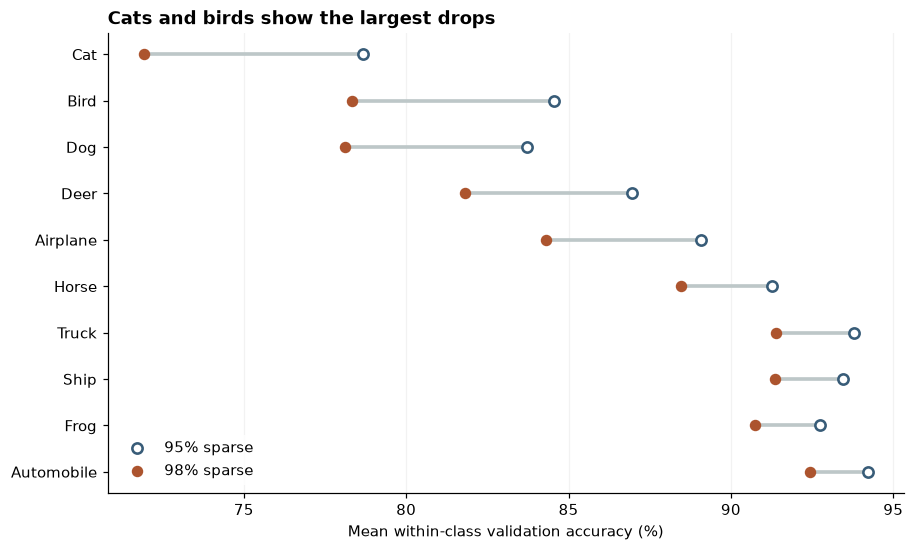

**Cat** accuracy declined from 78.68% to 71.92% (-6.76 pp). **Automobile** had the smallest decline, -1.77 pp. These measurements describe the same validation split.

In [8]:
classes = imp_classes.query("arch == 'resnet32' and seed == 0 and fraction == 25 and selector != 'Full data'")
class_grid = classes.groupby(["label", "sparsity"]).class_accuracy.mean().unstack()[[95, 98]]
class_grid["change"] = class_grid[98] - class_grid[95]
class_grid = class_grid.sort_values("change")
assert len(class_grid) == 10 and np.isclose(class_grid.change.mean(), d95.mean())
fig, ax = plt.subplots(figsize=(8.2, 4.9), layout="constrained")
y = np.arange(len(class_grid))
ax.hlines(y, class_grid[98], class_grid[95], color="#bdc7c8", linewidth=2.4)
ax.scatter(class_grid[95], y, s=45, facecolor="white", edgecolor="#385c78", linewidth=1.7, label="95% sparse", zorder=3)
ax.scatter(class_grid[98], y, s=42, color="#ac542e", label="98% sparse", zorder=3)
ax.set_yticks(y, labels=[v.capitalize() for v in class_grid.index])
ax.invert_yaxis()
ax.set(xlabel="Mean within-class validation accuracy (%)", title="Cats and birds show the largest drops")
ax.grid(axis="x", alpha=.16)
ax.legend(loc="lower left", frameon=True, facecolor="white", edgecolor="none")
plt.show()
largest, smallest = class_grid.iloc[0], class_grid.iloc[-1]
display(Markdown(f"**{class_grid.index[0].capitalize()}** accuracy declined from {largest[95]:.2f}% to "
                 f"{largest[98]:.2f}% ({largest['change']:+.2f} pp). **{class_grid.index[-1].capitalize()}** "
                 f"had the smallest decline, {smallest['change']:+.2f} pp. These measurements describe the same validation split."))

<a id="matched-comparisons"></a>

## Does using 25% of the training data for discovery improve on 20%?

These two ResNet-32 sweeps use seed 0, 90% sparsity, and the same 5,000 validation images. The discovery subsets contain 9,000 or 11,250 training images. Each subset receives 14,080 discovery updates, so the smaller subset cycles through its images more often. Both models then train on all 45,000 training images for 200 epochs.

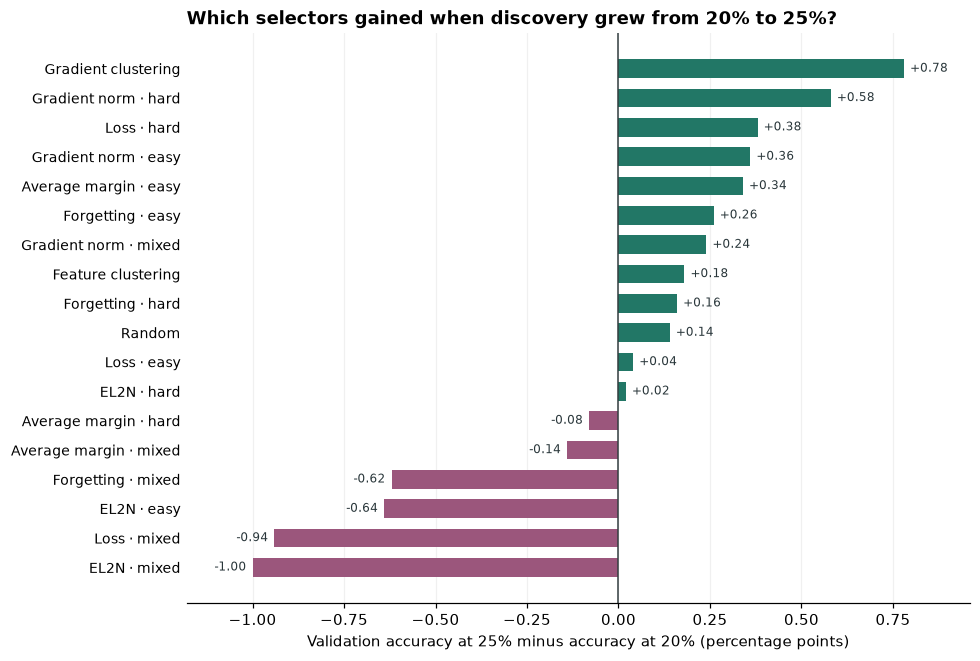

fraction,20% sweep,25% sweep
Mean across 18 selectors,90.73%,90.73%
Random subset,90.42%,90.56%
Best subset,91.46%,91.22%
Full-data IMP,89.92%,90.14%
Dense baseline,94.06%,94.06%


**The two subset sizes averaged 90.73% and 90.73%.** The mean paired change was +0.003 percentage points. Of 18 selector settings, 12 gained, 6 declined, and 0 tied. The largest increase was **Gradient clustering** (+0.78 pp), and the largest decrease was **EL2N · mixed** (-1.00 pp).

In [9]:
size_imp = imp.loc[imp["complete"] & imp["arch"].eq("resnet32") & imp["seed"].eq(0)
                   & imp["sparsity"].eq(90) & imp["fraction"].isin([20, 25])].copy()
size_all = size_imp.pivot(index="selector", columns="fraction", values="accuracy")[[20, 25]]
size_subset = size_all.drop(index="Full data")
assert size_subset.shape == (18, 2) and size_all.notna().all().all()
size_change = (size_subset[25] - size_subset[20]).round(4).sort_values()
size_mean_change = size_change.mean()

fig, ax = plt.subplots(figsize=(8.8, 5.9), layout="constrained")
positions = np.arange(len(size_change))
ax.barh(positions, size_change, height=.64,
        color=np.where(size_change >= 0, "#227766", "#9b567c"))
ax.set_yticks(positions, size_change.index, fontsize=9)
ax.set_xlim(min(-.1, size_change.min() - .18), max(.1, size_change.max() + .18))
ax.axvline(0, color="#343e40", lw=1)
for y, delta in enumerate(size_change):
    direction = 1 if delta >= 0 else -1
    ax.annotate(f"{delta:+.2f}", (delta, y), xytext=(4 * direction, 0),
                textcoords="offset points", va="center", ha="left" if direction > 0 else "right",
                fontsize=8, color="#29363a")
ax.set_title("Which selectors gained when discovery grew from 20% to 25%?",
             fontsize=12, loc="left", fontweight="bold")
ax.set_xlabel("Validation accuracy at 25% minus accuracy at 20% (percentage points)")
ax.grid(axis="x", alpha=.18)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0, pad=4)
plt.show()

size_references = pd.DataFrame({
    "Mean across 18 selectors": size_subset.mean(),
    "Random subset": size_subset.loc["Random"],
    "Best subset": size_subset.max(),
    "Full-data IMP": size_all.loc["Full data"],
    "Dense baseline": size_imp.groupby("fraction")["dense"].first(),
}).T
display(size_references.rename(columns={20: "20% sweep", 25: "25% sweep"}).style
        .format("{:.2f}%").set_caption("Seed 0 validation accuracy and sweep-specific controls"))
display(Markdown(
    f"**The two subset sizes averaged {size_subset[20].mean():.2f}% and {size_subset[25].mean():.2f}%.** "
    f"The mean paired change was {size_mean_change:+.3f} percentage points. "
    f"Of 18 selector settings, {(size_change > 0).sum()} gained, {(size_change < 0).sum()} declined, "
    f"and {(size_change == 0).sum()} tied. The largest increase was **{size_change.idxmax()}** "
    f"({size_change.max():+.2f} pp), and the largest decrease was **{size_change.idxmin()}** "
    f"({size_change.min():+.2f} pp)."
))

The full-data controls in these two sweeps share the same configuration ID. Each discovery run used the full training split and 70,400 updates. Their separately saved validation accuracies show run-to-run variation for that control. Only the 18 subset pairs above measure the effect of changing discovery size on this seed.

## Do selector gains transfer from ResNet-32 to VGG-19?

Both architectures used seed 0, 25% discovery subsets, 90% sparsity, and the same validation split. Each point compares a selector with the random subset on its own architecture. Points above and to the right of zero beat random on both. Each architecture supplies its own reference features and scores, so the same selector can choose different images.

arch,ResNet-32,VGG-19
Mean across 18 selectors,90.73%,93.23%
Lowest subset accuracy,90.04%,92.86%
Highest subset accuracy,91.22%,93.98%
Random subset,90.56%,93.08%
Full-data IMP,90.14%,94.04%
Dense baseline,94.06%,93.98%


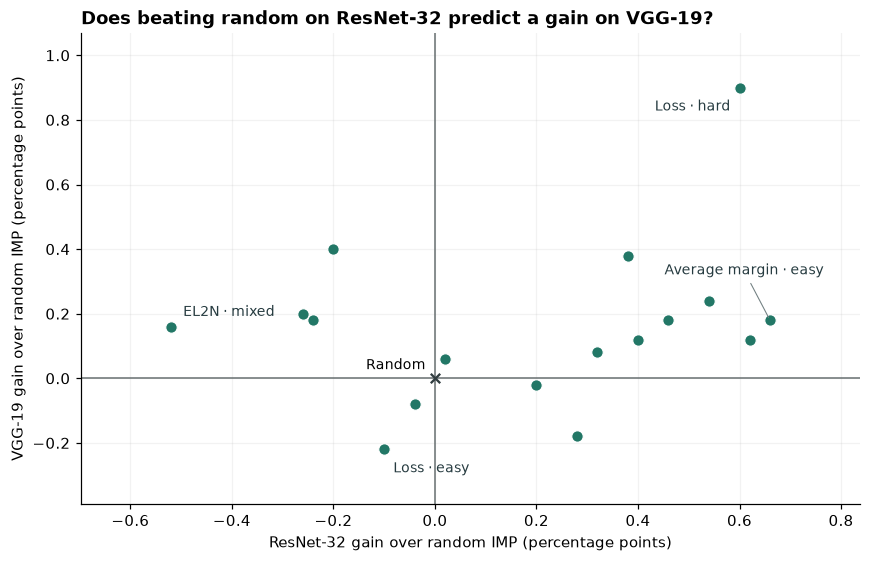

VGG-19 scored higher on **18 of 18** matched selector settings, by **2.50 pp** on average (range **2.02–3.20 pp**). Of the 17 nonrandom selectors, **9** beat random on both architectures. Their rank correlation was **0.19** (Spearman). **Average margin · easy** led on ResNet-32 and **Loss · hard** led on VGG-19.

The pruning masks kept **46,187 of 461,872** eligible ResNet-32 weights and **2,002,400 of 20,024,000** on VGG-19. VGG-19 retained **43.4×** as many weights. These accuracy and ranking comparisons describe one paired seed.

In [10]:
architecture_imp = imp.loc[imp["complete"] & imp["seed"].eq(0) & imp["fraction"].eq(25)
                           & imp["sparsity"].eq(90) & imp["arch"].isin(["resnet32", "vgg19"])]
arch_all = architecture_imp.pivot(index="selector", columns="arch", values="accuracy")[["resnet32", "vgg19"]]
arch_subset = arch_all.drop(index="Full data")
assert arch_subset.shape == (18, 2) and arch_all.notna().all().all()
arch_gains = (arch_subset - arch_subset.loc["Random"]).round(4).drop(index="Random")
arch_labels = {"resnet32": "ResNet-32", "vgg19": "VGG-19"}
arch_references = pd.DataFrame({
    "Mean across 18 selectors": arch_subset.mean(),
    "Lowest subset accuracy": arch_subset.min(),
    "Highest subset accuracy": arch_subset.max(),
    "Random subset": arch_subset.loc["Random"],
    "Full-data IMP": arch_all.loc["Full data"],
    "Dense baseline": architecture_imp.groupby("arch")["dense"].first(),
}).T
display(arch_references.rename(columns=arch_labels).style.format("{:.2f}%")
        .set_caption("Validation accuracy at 90% weight sparsity, with a dense reference for each architecture"))

fig, ax = plt.subplots(figsize=(7.8, 5.0), layout="constrained")
ax.axhline(0, lw=1, color="#687071", zorder=1)
ax.axvline(0, lw=1, color="#687071", zorder=1)
ax.scatter(arch_gains["resnet32"], arch_gains["vgg19"], s=57, color="#227766",
           edgecolor="white", linewidth=.8, zorder=3)
ax.scatter([0], [0], color="#313d40", s=38, marker="x", zorder=4)
ax.annotate("Random", (0, 0), xytext=(-6, 6), textcoords="offset points", ha="right", fontsize=9)
point_labels = {arch_gains["resnet32"].idxmin(): (8, 7),
                arch_gains["vgg19"].idxmin(): (6, -15),
                arch_gains["resnet32"].idxmax(): (35, 30),
                arch_gains["vgg19"].idxmax(): (-6, -15)}
for setting, (dx, dy) in point_labels.items():
    px, py = arch_gains.loc[setting]
    ax.annotate(setting, (px, py), xytext=(dx, dy), textcoords="offset points",
                ha="right" if setting == arch_gains["resnet32"].idxmax() or dx < 0 else "left",
                fontsize=9, color="#263b40",
                arrowprops={"arrowstyle": "-", "lw": .7, "color": "#728082"} if dy == 30 else None)
ax.margins(x=.15, y=.15)
ax.set(xlabel="ResNet-32 gain over random IMP (percentage points)",
       ylabel="VGG-19 gain over random IMP (percentage points)")
ax.set_title("Does beating random on ResNet-32 predict a gain on VGG-19?",
             loc="left", fontsize=12, fontweight="bold")
ax.grid(alpha=.16)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

arch_abs_gap = arch_subset["vgg19"] - arch_subset["resnet32"]
arch_rank_corr = arch_gains.rank().corr().at["resnet32", "vgg19"]
arch_masks = architecture_imp.groupby("arch")[["eligible", "surviving"]].first()
assert architecture_imp.groupby("arch")[["eligible", "surviving"]].nunique().eq(1).all().all()
display(Markdown(
    f"VGG-19 scored higher on **{(arch_abs_gap > 0).sum()} of {len(arch_abs_gap)}** matched selector settings, "
    f"by **{arch_abs_gap.mean():.2f} pp** on average (range **{arch_abs_gap.min():.2f}–{arch_abs_gap.max():.2f} pp**). "
    f"Of the {len(arch_gains)} nonrandom selectors, **{arch_gains.gt(0).all(axis=1).sum()}** beat random "
    f"on both architectures. Their rank correlation was **{arch_rank_corr:.2f}** (Spearman). "
    f"**{arch_subset['resnet32'].idxmax()}** led on ResNet-32 and **{arch_subset['vgg19'].idxmax()}** led on VGG-19.\n\n"
    f"The pruning masks kept **{arch_masks.at['resnet32', 'surviving']:,} of "
    f"{arch_masks.at['resnet32', 'eligible']:,}** eligible ResNet-32 weights and "
    f"**{arch_masks.at['vgg19', 'surviving']:,} of {arch_masks.at['vgg19', 'eligible']:,}** on VGG-19. "
    f"VGG-19 retained **{arch_masks.at['vgg19', 'surviving'] / arch_masks.at['resnet32', 'surviving']:.1f}×** "
    f"as many weights. These accuracy and ranking comparisons describe one paired seed."
))

<a id="all-results"></a>

## All 152 IMP validation accuracies

Read a column to compare selectors under one setting. Read across a row to follow the same selector. The final row gives the full-data IMP result associated with each sweep. For ResNet-32 seed 0 at 90% sparsity, the two full-data entries are separate measurements of the same nominal control.

In [11]:
lookup = imp.pivot(index="selector", columns=cohort, values="accuracy").sort_index(axis=1)
ordered_names = [name for family in family_names.values() for name in
                 ([f"{family} · {d}" for d in ["easy", "hard", "mixed"]]
                  if f"{family} · easy" in lookup.index else [family])]
lookup = lookup.loc[ordered_names + ["Full data"]]
lookup.columns = pd.MultiIndex.from_tuples(
    [(arch_names[a], f"Seed {s}", f"{f}% subset", f"{z}% sparse") for a, s, f, z in lookup.columns],
    names=[None] * 4)
assert lookup.size == len(imp) and lookup.notna().all().all()
display(lookup.rename_axis("Discovery set").style.format("{:.2f}%")
        .set_caption("Epoch-200 validation accuracy. Each column is one sweep."))